[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/DaTrollMon/schutz-gr-solutions-3rd/blob/main/Ch.2/Problem_2.25.ipynb)

# Chapter 2, Problem 25 — the Doppler shift at an angle

**Problem.**
- **(a)** Let $\bar{\mathcal O}$ move with speed $v$ in the $x$ direction relative to $\mathcal O$. Let a photon have frequency $\nu$ in $\mathcal O$ and move at angle $\theta$ to $\mathcal O$'s $x$ axis. Show that its frequency in $\bar{\mathcal O}$ is
$$
\frac{\bar\nu}{\nu} = \frac{1 - v\cos\theta}{\sqrt{1 - v^2}}. \tag{2.42}
$$
- **(b)** Even when the photon moves perpendicular to the $x$ axis ($\theta = \pi/2$) there is a shift — the **transverse Doppler shift**, due to time dilation. At what angle $\theta$ does the photon have to move so that there is no Doppler shift between $\mathcal O$ and $\bar{\mathcal O}$?
- **(c)** Use Eqs. (2.35) and (2.38) to calculate Eq. (2.42).

In [1]:
# --- setup: shared code for Colab / Codespaces ---
# Locally (uv sync) this does nothing. On Colab it installs the shared `schutz_gr`
# package from GitHub the first time the notebook runs.
try:
    import schutz_gr
except ImportError:
    %pip install -q "git+https://github.com/DaTrollMon/schutz-gr-solutions-3rd"
    import schutz_gr

## (a) By Lorentz-transforming the four-momentum

**The photon's four-momentum in $\mathcal O$.** Energy $E = h\nu$ (Eq. 2.38). It's null, so $|\mathbf p| = E$ (Eq. 2.37), directed at angle $\theta$ to $x$ (choose the $x$–$y$ plane):
$$
\vec p \xrightarrow{\mathcal O} h\nu\,(1,\ \cos\theta,\ \sin\theta,\ 0).
$$
**Transform the time component** with the boost along $x$:
$$
\bar E = p^{\bar0} = \gamma\big(p^0 - v\,p^1\big) = \gamma\,h\nu\,(1 - v\cos\theta).
$$
**Frequency in $\bar{\mathcal O}$:** $\bar E = h\bar\nu$ (quantum relation holds in every frame), so
$$
\boxed{\frac{\bar\nu}{\nu} = \gamma(1 - v\cos\theta) = \frac{1 - v\cos\theta}{\sqrt{1 - v^2}}}\qquad\blacksquare
$$
**Checks.** $\theta = 0$ (photon moving in the same direction as $\bar{\mathcal O}$): $\frac{1 - v}{\sqrt{1 - v^2}} = \sqrt{\frac{1-v}{1+v}}$, Eq. (2.39), a redshift ✓. $\theta = \pi$ (head-on): $\sqrt{\frac{1+v}{1-v}}$, a blueshift ✓.

## (b) Transverse shift, and the angle of zero shift

At $\theta = \pi/2$: $\bar\nu/\nu = \gamma > 1$. $\bar{\mathcal O}$ sees a **blueshift** even though, in $\mathcal O$, the photon has no component along the relative motion. It's pure time dilation: $\bar{\mathcal O}$'s clocks are slow as judged by $\mathcal O$, so $\bar{\mathcal O}$ counts more wave crests per unit of his own time. (At $\pi/2$ *in $\bar{\mathcal O}$'s frame* instead, the shift is the reciprocal $1/\gamma$, a redshift — the angle is frame-dependent too: aberration.)

**No shift:** set $\bar\nu = \nu$:
$$
1 - v\cos\theta = \sqrt{1 - v^2}\quad\Longrightarrow\quad
\boxed{\cos\theta = \frac{1 - \sqrt{1 - v^2}}{v}}
$$
Since $0 < 1 - \sqrt{1-v^2} < v$ for $0 < v < 1$, this always has a solution with $0 < \theta < \pi/2$: the photon must move slightly *forward*, enough that the longitudinal redshift cancels the transverse blueshift. For small $v$: $\cos\theta \approx v/2$, i.e. $\theta \approx \pi/2 - v/2$. For $v = 0.6$: $\cos\theta = 0.2/0.6 = 1/3$, $\theta = 70.5^\circ$.

## (c) Frame-invariant method: $\bar E = -\vec p\cdot\vec U_{\text{obs}}$

Eq. (2.35): the energy measured by an observer with four-velocity $\vec U_{\text{obs}}$ is $\bar E = -\vec p\cdot\vec U_{\text{obs}}$, computable in *any* frame. In $\mathcal O$, $\bar{\mathcal O}$'s four-velocity is $\vec U_{\text{obs}} \to \gamma(1, v, 0, 0)$. Using the components above and Eq. (2.26):
$$
\vec p\cdot\vec U_{\text{obs}} = h\nu\gamma\big(-1\cdot1 + \cos\theta\cdot v + \sin\theta\cdot0\big) = -h\nu\gamma(1 - v\cos\theta),
$$
$$
h\bar\nu = \bar E = -\vec p\cdot\vec U_{\text{obs}} = h\nu\gamma(1 - v\cos\theta)\quad\Longrightarrow\quad \frac{\bar\nu}{\nu} = \frac{1 - v\cos\theta}{\sqrt{1 - v^2}} . \qquad\checkmark
$$
No transformation matrix needed: one dot product in $\mathcal O$'s own components.

In [2]:
import sympy as sp
from schutz_gr import boost_matrix, four_velocity, minkowski_dot
h, nu, v, th = sp.symbols("h nu v theta", positive=True)
p = h*nu*sp.Matrix([1, sp.cos(th), sp.sin(th), 0])
print("(a) ν̄/ν =", sp.simplify((boost_matrix(v) * p)[0] / (h*nu)))
print("(c) −p·U_obs/(hν) =", sp.simplify(-minkowski_dot(p, four_velocity([v, 0, 0])) / (h*nu)))
cos0 = (1 - sp.sqrt(1 - v**2)) / v
print("(b) cos θ₀ =", cos0, "  series:", sp.series(cos0, v, 0, 4), "  at v = 0.6:", sp.nsimplify(cos0.subs(v, sp.Rational(3, 5))),
      "→", float(sp.deg(sp.acos(cos0.subs(v, sp.Rational(3, 5))))), "deg")

(a) ν̄/ν = (-v*cos(theta) + 1)/sqrt(1 - v**2)
(c) −p·U_obs/(hν) = (-v*cos(theta) + 1)/sqrt(1 - v**2)
(b) cos θ₀ = (1 - sqrt(1 - v**2))/v   series: v/2 + v**3/8 + O(v**4)   at v = 0.6: 1/3 → 70.52877936550931 deg


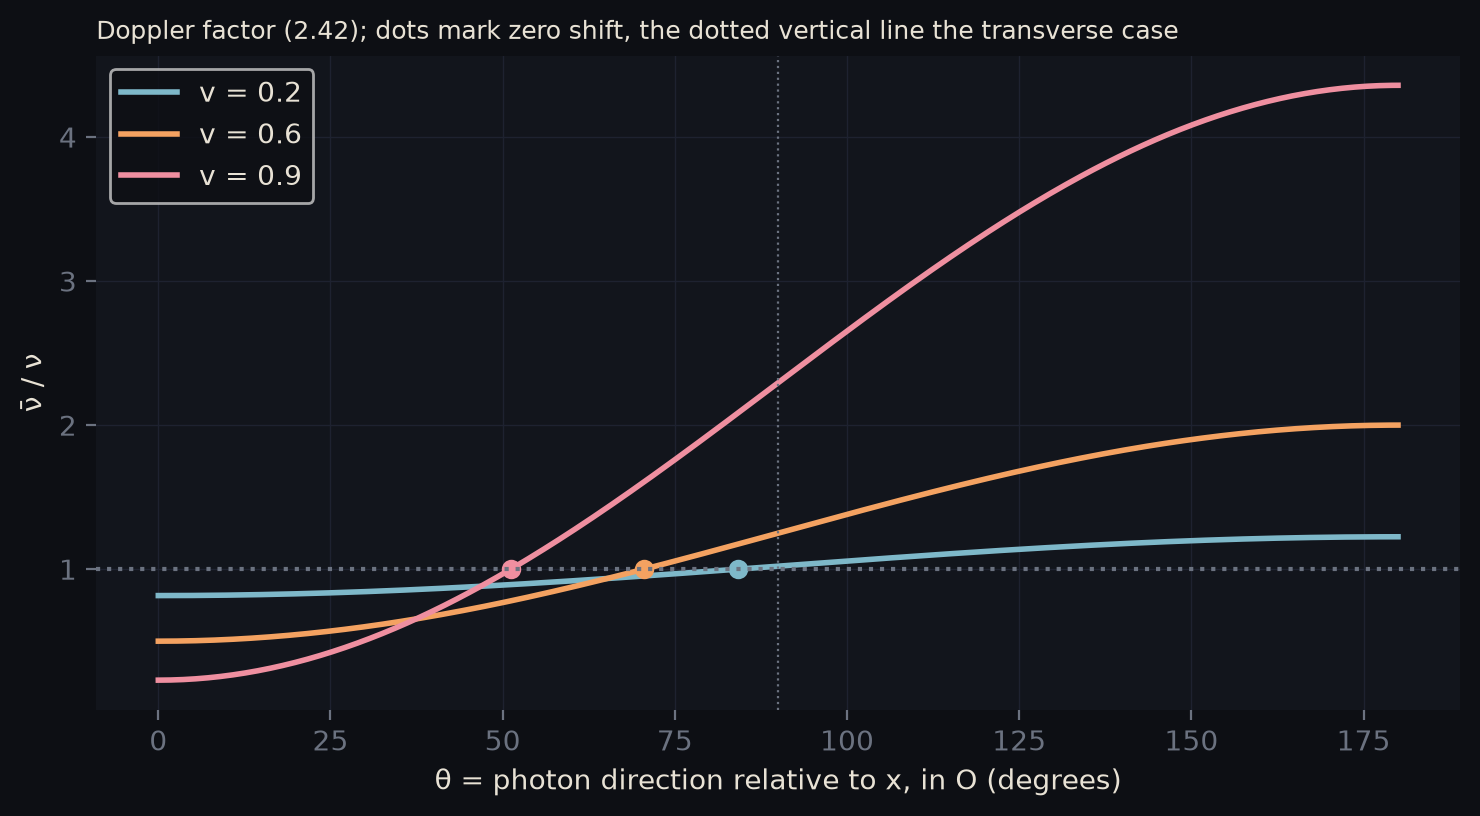

In [3]:
import numpy as np
import matplotlib.pyplot as plt
from schutz_gr.diagrams import COLORS
%config InlineBackend.figure_format = 'retina'
TH = np.linspace(0, np.pi, 400)
fig, ax = plt.subplots(figsize=(7.5, 4.2)); fig.patch.set_facecolor(COLORS["bg"]); ax.set_facecolor(COLORS["panel"])
for vv, col in ((0.2, "teal"), (0.6, "amber"), (0.9, "rose")):
    ax.plot(np.degrees(TH), (1 - vv*np.cos(TH))/np.sqrt(1 - vv**2), color=COLORS[col], lw=2, label=f"v = {vv}")
    th0 = np.degrees(np.arccos((1 - np.sqrt(1 - vv**2))/vv)); ax.plot([th0], [1], "o", color=COLORS[col])
ax.axhline(1, color=COLORS["grey"], ls=":"); ax.axvline(90, color=COLORS["grey"], ls=":", lw=0.8)
ax.set_xlabel("θ = photon direction relative to x, in O (degrees)", color=COLORS["text"]); ax.set_ylabel("ν̄ / ν", color=COLORS["text"])
ax.set_title("Doppler factor (2.42); dots mark zero shift, the dotted vertical line the transverse case", color=COLORS["text"], loc="left", fontsize=9)
ax.tick_params(colors=COLORS["grey"]); ax.grid(color=COLORS["grid"], lw=0.5, which="both")
for s in ax.spines.values(): s.set_visible(False)
leg = ax.legend(); leg.get_frame().set_facecolor(COLORS["bg"])
for tx in leg.get_texts(): tx.set_color(COLORS["text"])
plt.tight_layout(); plt.show()